# 05 — Time Series Classification

**Input:** `CMI_timeseries_prepared.pkl` (prodotto da `02_data_preparation.ipynb`). I modelli lenti sono salvati in `results_cache/`.

**Task:** predire `sii_binary` da una finestra di `enmo` (o dai 5 canali), valutando sia **per finestra** sia **per id** (media dei punteggi delle finestre del soggetto, misura principale).

**Cosa è stato fatto in questo notebook:**
- Protocollo: split e fold raggruppati per id (P5), scelta di iperparametri/rappresentazione/soglia solo in CV sul train (ROC-AUC per id), test valutato una sola volta.
- **Riferimento:** regressione logistica sul solo `enmo` medio.
- **KNN** con distanza euclidea e Manhattan su 4 rappresentazioni (livello/forma, 200 step/PAA-50).
- **KNN-DTW** (serie intera vs PAA-50, libera vs banda di Sakoe-Chiba).
- **Shapelet** (`RandomShapeletTransform` di `aeon`) con analisi degli shapelet trovati e confronto con motif/discord.
- **MiniRocket** su `enmo` e sui 5 canali.
- Confronto finale sul test con IC95 bootstrap, curve ROC, matrici di confusione; conclusioni generali del progetto.

**Risultati principali:** i migliori arrivano ad AUC per id ≈ 0.69–0.71, ma nessuno batte in modo dimostrabile il riferimento (0.685): il segnale sta nel **livello di attività diurna**, non nella forma. Gli shapelet sovradattano (0.50 sul test).

### Setup

In [ ]:
import pickle, time, os, warnings
warnings.filterwarnings('ignore', category=RuntimeWarning, module='sklearn')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

# dataset preparato prodotto da 02_data_preparation.ipynb
with open('CMI_timeseries_prepared.pkl', 'rb') as f:
    PREP = pickle.load(f)
tr, te = PREP['train_idx'], PREP['test_idx']
y, ids, meta = PREP['y'], PREP['ids'], PREP['meta']
enmo_clean = PREP['X_raw'][:, 0, :].astype(np.float64)
SEED = PREP['params']['RANDOM_STATE']
C0, C1 = '#2a78d6', '#eb6834'   # colori classe 0 / classe 1

import time
from numpy.lib.stride_tricks import sliding_window_view
from aeon.distances import dtw_pairwise_distance

# --- helper condivisi con 03_motif_discord e 04_clustering (stesse definizioni) ---
CACHE = 'results_cache'
os.makedirs(CACHE, exist_ok=True)

def cached(name, fn):
    """Salva su disco i calcoli lenti: per rifarli basta cancellare results_cache/."""
    path = os.path.join(CACHE, name + '.pkl')
    if os.path.exists(path):
        with open(path, 'rb') as f:
            return pickle.load(f)
    out = fn()
    with open(path, 'wb') as f:
        pickle.dump(out, f)
    return out

def dtw_matrix(Xa, Xb=None, r=None):
    """Matrice DTW (radice del costo, come tslearn) con banda di Sakoe-Chiba di raggio r."""
    window = None if r is None else r / (Xa.shape[1] - 1)
    return np.sqrt(dtw_pairwise_distance(Xa[:, None, :], None if Xb is None else Xb[:, None, :], window=window, n_jobs=-1))

def znorm_rows(a, eps=1e-8):
    s = a.std(axis=-1, keepdims=True)
    return (a - a.mean(axis=-1, keepdims=True)) / np.where(s < eps, 1.0, s)

def min_dist(S, X, chunk=500):
    """Distanza z-normalizzata fra la sottosequenza S e la sua migliore posizione in ogni serie di X."""
    S = znorm_rows(np.asarray(S, float)); L = len(S); out = []
    for a in range(0, len(X), chunk):
        W = znorm_rows(sliding_window_view(X[a:a + chunk], L, axis=1))
        out.append(np.sqrt(((W - S) ** 2).sum(axis=2)).min(axis=1))
    return np.concatenate(out) / np.sqrt(L)

def id_auc(score, y_w, id_w):
    g = pd.DataFrame({'s': score, 'y': y_w, 'id': id_w}).groupby('id').agg(s=('s', 'mean'), y=('y', 'first'))
    return roc_auc_score(g.y, g.s)

# pool bilanciato di finestre di train (una per id), identico a quello di 03_motif_discord:
# serve all'analisi degli shapelet per confrontarli con il contrasto fra classi
rng_c = np.random.default_rng(SEED)
tr_meta = meta.iloc[tr]
pool = {c: np.array([rng_c.choice(g.index.values) for _, g in tr_meta[tr_meta.y == c].groupby('id')]) for c in [0, 1]}
n_pool = min(len(pool[0]), len(pool[1]))
pool = {c: rng_c.choice(pool[c], size=n_pool, replace=False) for c in [0, 1]}

## TIME SERIES CLASSIFICATION

**Task:** data una finestra di `enmo` (o dei 5 canali), predire `sii_binary`. Poiché l'etichetta è del soggetto, riportiamo due livelli:

- **per finestra**: ogni giornata viene classificata da sola;
- **per id**: si fa la media dei punteggi delle finestre di un soggetto. È la misura principale, perché i soggetti sono le vere unità indipendenti.

**Protocollo:**
- split e fold di P5, raggruppati per id: nessun soggetto sta da entrambe le parti;
- iperparametri, rappresentazione e soglia di decisione si scelgono solo con la CV sul train, in base alla ROC-AUC per id;
- il test viene valutato una sola volta, alla fine, con il modello migliore di ogni famiglia;
- metriche: ROC-AUC, balanced accuracy e F1 macro. L'accuracy è fuorviante con classi 2:1 (vedi EDA);
- riferimento: una **regressione logistica sul solo `enmo` medio** della finestra. Serve per capire se i metodi su serie temporali aggiungono qualcosa al semplice livello di attività.

In [68]:
from sklearn.metrics import pairwise_distances, balanced_accuracy_score, f1_score, roc_curve, confusion_matrix
from sklearn.linear_model import LogisticRegression, RidgeClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

ytr, yte, idtr, idte = y[tr], y[te], ids[tr], ids[te]
cv_folds = meta['cv_fold'].values[tr]
X_global_all, X_znorm_all = PREP['X_global'].astype(np.float64), PREP['X_znorm'].astype(np.float64)
reprs = {
    'enmo livello, 200 step': X_global_all[:, 0, :],
    'enmo forma, 200 step': X_znorm_all[:, 0, :],
    'enmo livello, PAA-50': PREP['enmo_paa_global'].astype(np.float64),
    'enmo forma, PAA-50': PREP['enmo_paa_z'].astype(np.float64),
}

def by_id(score, id_w, y_w):
    g = pd.DataFrame({'s': score, 'y': y_w, 'id': id_w}).groupby('id').agg(s=('s', 'mean'), y=('y', 'first'))
    return g.s.values, g.y.values

def best_threshold(s, y_):
    grid = np.unique(np.quantile(s, np.linspace(0.02, 0.98, 97)))
    return float(grid[int(np.argmax([f1_score(y_, s >= t, average='macro') for t in grid]))])

def cv_summary(oof):
    s_id, y_id = by_id(oof, idtr, ytr)
    return {'AUC id': roc_auc_score(y_id, s_id), 'AUC finestra': roc_auc_score(ytr, oof)}

def knn_cv(D, ks):
    """D = distanze train x train. Restituisce gli score fuori fold per ogni k (voto dei k vicini degli altri fold)."""
    oof = {k: np.zeros(len(ytr)) for k in ks}
    for f in np.unique(cv_folds):
        va, fit = cv_folds == f, cv_folds != f
        nn = np.argsort(D[np.ix_(va, fit)], axis=1)[:, :max(ks)]
        votes = ytr[fit][nn].cumsum(axis=1)
        for k in ks:
            oof[k][va] = votes[:, k - 1] / k
    return oof

def knn_test(D_te_tr, k):
    nn = np.argsort(D_te_tr, axis=1)[:, :k]
    return ytr[nn].mean(axis=1)

KS = [1, 5, 11, 21, 51, 101, 201]
results, oof_store = [], {}

# riferimento
mean_enmo = enmo_clean.mean(axis=1, keepdims=True)
def fit_baseline(Xa, ya):
    return make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced')).fit(Xa, ya)
oof = np.zeros(len(ytr))
for f in np.unique(cv_folds):
    va = cv_folds == f
    oof[va] = fit_baseline(mean_enmo[tr][~va], ytr[~va]).decision_function(mean_enmo[tr][va])
oof_store['baseline'] = oof
results.append({'famiglia': 'Riferimento', 'configurazione': 'logistica su enmo medio', **cv_summary(oof)})
print(results[-1])

{'famiglia': 'Riferimento', 'configurazione': 'logistica su enmo medio', 'AUC id': np.float64(0.6678271308523409), 'AUC finestra': np.float64(0.6468850632884877)}


### KNN con distanza euclidea e Manhattan

Confrontano i timestep alla stessa posizione. Dato che le finestre sono in fase (P4), il confronto ha senso. Valutiamo tutte e quattro le rappresentazioni, con `k` fino a 201 perché il segnale atteso è debole e un voto fra molti vicini può ridurre il rumore.

In [69]:
knn_rows = []
for rep_name, Xr in reprs.items():
    for metric, fam in [('euclidean', 'KNN euclidea'), ('manhattan', 'KNN Manhattan')]:
        D = pairwise_distances(Xr[tr], metric=metric, n_jobs=-1)
        oofs = knn_cv(D, KS)
        for k in KS:
            row = {'famiglia': fam, 'configurazione': f'{rep_name}, k={k}', 'rep': rep_name, 'metric': metric, 'k': k, **cv_summary(oofs[k])}
            knn_rows.append(row); oof_store[(fam, rep_name, k)] = oofs[k]
        del D
knn_table = pd.DataFrame(knn_rows)
print(knn_table.pivot_table(index=['metric', 'rep'], columns='k', values='AUC id').round(3).to_string())

k                                   1      5      11     21     51     101    201
metric    rep                                                                    
euclidean enmo forma, 200 step    0.558  0.575  0.583  0.609  0.597  0.601  0.598
          enmo forma, PAA-50      0.576  0.585  0.594  0.612  0.595  0.592  0.594
          enmo livello, 200 step  0.540  0.629  0.635  0.629  0.631  0.640  0.641
          enmo livello, PAA-50    0.608  0.625  0.653  0.649  0.656  0.659  0.667
manhattan enmo forma, 200 step    0.517  0.497  0.501  0.523  0.551  0.535  0.561
          enmo forma, PAA-50      0.577  0.556  0.566  0.561  0.566  0.573  0.578
          enmo livello, 200 step  0.568  0.587  0.606  0.611  0.600  0.609  0.623
          enmo livello, PAA-50    0.552  0.574  0.621  0.640  0.665  0.678  0.669


### KNN con DTW

Confrontiamo PAA-50 e serie intera, DTW libera e con banda di Sakoe-Chiba, livello e forma. Usiamo la DTW di `aeon`, che dà gli stessi valori di `tslearn` ma è circa 50 volte più veloce, quindi possiamo provare anche la serie intera.

In [70]:
dtw_configs = {
    'enmo forma, PAA-50, r=3': ('enmo forma, PAA-50', 3),
    'enmo forma, PAA-50, libera': ('enmo forma, PAA-50', None),
    'enmo livello, PAA-50, r=3': ('enmo livello, PAA-50', 3),
    'enmo livello, PAA-50, libera': ('enmo livello, PAA-50', None),
    'enmo forma, 200 step, r=12': ('enmo forma, 200 step', 12),
    'enmo livello, 200 step, r=12': ('enmo livello, 200 step', 12),
    'enmo forma, 200 step, libera': ('enmo forma, 200 step', None),
    'enmo livello, 200 step, libera': ('enmo livello, 200 step', None),
}

dtw_rows = []
for cfg, (rep_name, r) in dtw_configs.items():
    t0 = time.perf_counter()
    Xr = reprs[rep_name]
    D = dtw_matrix(Xr[tr], None, r).astype(np.float32)
    oofs = knn_cv(D, KS)
    for k in KS:
        dtw_rows.append({'famiglia': 'KNN DTW', 'configurazione': f'{cfg}, k={k}', 'cfg': cfg, 'k': k, **cv_summary(oofs[k])})
        oof_store[('KNN DTW', cfg, k)] = oofs[k]
    del D
    print(f"{cfg}: {time.perf_counter() - t0:.0f} s", flush=True)
dtw_table = pd.DataFrame(dtw_rows)
print(dtw_table.pivot_table(index='cfg', columns='k', values='AUC id').round(3).to_string())

enmo forma, PAA-50, r=3: 6 s


enmo forma, PAA-50, libera: 12 s


enmo livello, PAA-50, r=3: 6 s


enmo livello, PAA-50, libera: 12 s


enmo forma, 200 step, r=12: 76 s


enmo livello, 200 step, r=12: 78 s


enmo forma, 200 step, libera: 165 s


enmo livello, 200 step, libera: 169 s


k                                 1      5      11     21     51     101    201
cfg                                                                            
enmo forma, 200 step, libera    0.462  0.518  0.500  0.519  0.543  0.568  0.557
enmo forma, 200 step, r=12      0.572  0.606  0.605  0.595  0.611  0.600  0.592
enmo forma, PAA-50, libera      0.516  0.603  0.567  0.567  0.570  0.590  0.579
enmo forma, PAA-50, r=3         0.572  0.598  0.595  0.579  0.579  0.585  0.574
enmo livello, 200 step, libera  0.514  0.609  0.626  0.623  0.627  0.646  0.651
enmo livello, 200 step, r=12    0.578  0.592  0.630  0.642  0.642  0.654  0.655
enmo livello, PAA-50, libera    0.522  0.551  0.596  0.621  0.641  0.648  0.657
enmo livello, PAA-50, r=3       0.528  0.583  0.605  0.623  0.638  0.659  0.658


### Shapelet

Uno **shapelet** è una sottosequenza scelta perché la sua distanza dalle serie separa bene le classi. Usiamo `RandomShapeletTransform` di `aeon`: estrae candidati a caso dal train, tiene quelli con il miglior guadagno informativo e trasforma ogni serie nel vettore delle distanze dagli shapelet. Su questo vettore si allena una regressione logistica.

Lavoriamo su `enmo forma, PAA-50`, con lunghezze da 6 a 24 segmenti (da 24 a 96 step). Le distanze sono z-normalizzate, quindi gli shapelet vedono **solo la forma**. La scoperta avviene dentro ogni fold, così i candidati non vedono mai i dati di validazione.

In [71]:
from aeon.transformations.collection.shapelet_based import RandomShapeletTransform

S_PARAMS = dict(n_shapelet_samples=3000, max_shapelets=100, min_shapelet_length=6, max_shapelet_length=24, n_jobs=-1, random_state=SEED)
X_st = reprs['enmo forma, PAA-50'][:, None, :]

def fit_shapelets(Xa, ya):
    st = RandomShapeletTransform(**S_PARAMS)
    Fa = st.fit_transform(Xa, ya)
    clf = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', C=0.1, max_iter=2000)).fit(Fa, ya)
    return st, clf

def shapelet_cv():
    oof = np.zeros(len(ytr))
    for f in np.unique(cv_folds):
        va = cv_folds == f
        st, clf = fit_shapelets(X_st[tr][~va], ytr[~va])
        oof[va] = clf.decision_function(st.transform(X_st[tr][va]))
        print('fold', f, 'completato', flush=True)
    return oof

t0 = time.perf_counter()
oof_shp = cached('shapelet_oof', shapelet_cv)
oof_store['shapelet'] = oof_shp
results.append({'famiglia': 'Shapelet', 'configurazione': 'RST su enmo forma PAA-50 + logistica', **cv_summary(oof_shp)})
print(results[-1], f'{time.perf_counter() - t0:.0f} s')

{'famiglia': 'Shapelet', 'configurazione': 'RST su enmo forma PAA-50 + logistica', 'AUC id': np.float64(0.6548619447779112), 'AUC finestra': np.float64(0.5796719749023058)} 0 s


shapelet tenuti: 100  |  per classe: {0: 50, 1: 50}
lunghezza in segmenti (mediana): 20  |  guadagno informativo: max 0.0170, mediano 0.0108


 rank  classe sorgente  più vicino alla classe     IG  lunghezza (step)  inizio (step)  id sorgente  AUC id train  AUC id test  dist. classe propria  dist. altra classe
    1                0                       0 0.0170                76             80          736         0.652        0.484                 0.932               0.988
    2                1                       0 0.0166                68             24         2735         0.684        0.518                 1.039               1.003
    3                0                       0 0.0149                84              4          901         0.674        0.465                 1.014               1.041
    4                0                       0 0.0147                80             12          699         0.648        0.471                 0.883               0.923
    5                1                       0 0.0137                80              0         1252         0.685        0.487                 1.016       

su tutti i 100 shapelet, AUC id: train mediana 0.629, test mediana 0.496, test massima 0.583, quota sopra 0.5 nel test 46%
id sorgente distinti fra i 100 shapelet: 73  |  id con più shapelet: 4


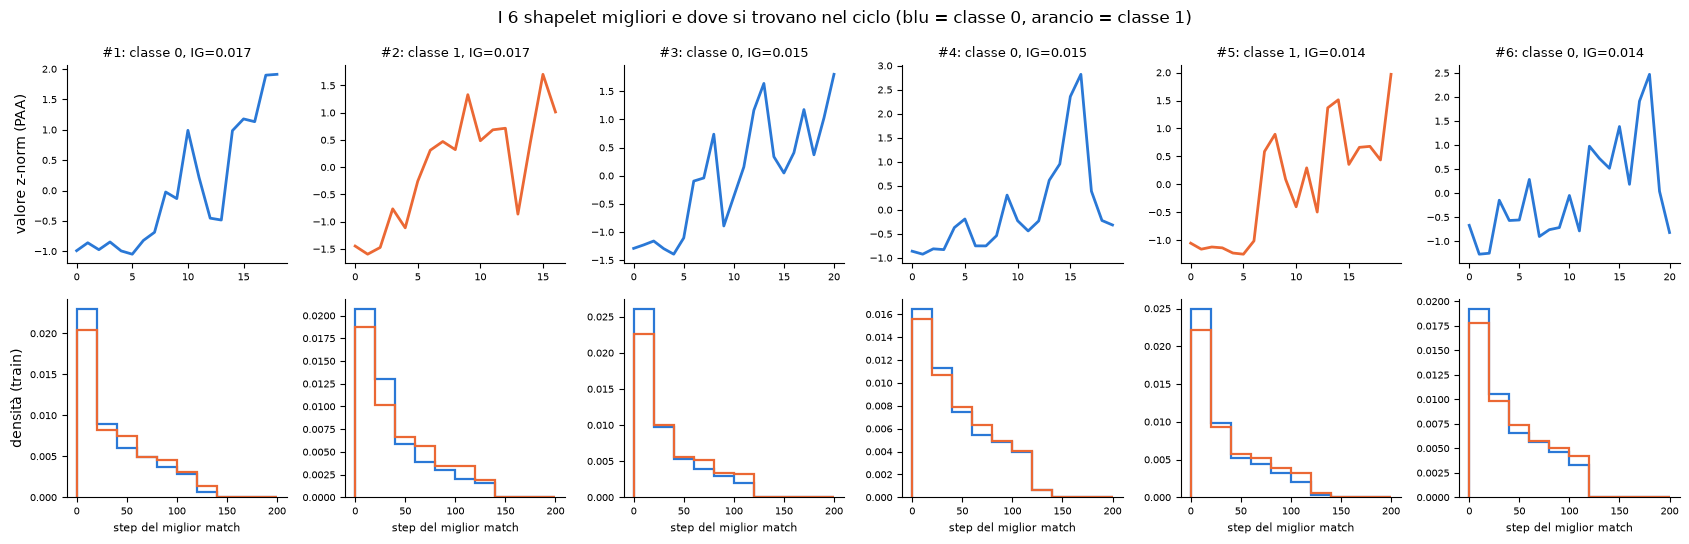

In [72]:
def fit_final_shapelets():
    st, clf = fit_shapelets(X_st[tr], ytr)
    return st, clf, clf.decision_function(st.transform(X_st[te]))
st_final, clf_final, score_shp_te = cached('shapelet_final', fit_final_shapelets)

# ogni voce: (guadagno informativo, lunghezza, inizio, canale, indice della serie di train, classe, valori z-normalizzati)
shp_list = sorted(st_final.shapelets, key=lambda s: -s[0])
print(f"shapelet tenuti: {len(shp_list)}  |  per classe: {pd.Series([int(s[5]) for s in shp_list]).value_counts().to_dict()}")
print(f"lunghezza in segmenti (mediana): {np.median([s[1] for s in shp_list]):.0f}  |  guadagno informativo: max {shp_list[0][0]:.4f}, mediano {np.median([s[0] for s in shp_list]):.4f}")

shape_paa = reprs['enmo forma, PAA-50']
rows_shp = []
for rank, s in enumerate(shp_list[:6]):
    ig, L, start, _, inst, cls, vals = s
    vals = np.asarray(vals).ravel(); cls = int(cls); src_w = tr[int(inst)]
    d_tr = min_dist(vals, shape_paa[tr]); d_te = min_dist(vals, shape_paa[te])
    # la classe sorgente non dice da che parte separa lo shapelet: la direzione si stabilisce sul train
    sign = -1 if id_auc(-d_tr, ytr, idtr) >= 0.5 else 1   # -1: più vicino = più classe 1
    # legame con motif/discord, sulla serie originale e sullo stesso pool del contrasto (esclusa la finestra sorgente)
    Q = enmo_clean[src_w, 4 * int(start):4 * int(start) + 4 * int(L)]
    own = [w for w in pool[cls] if ids[w] != ids[src_w]]; other = pool[1 - cls]
    d_own, d_other = np.median(min_dist(Q, enmo_clean[own])), np.median(min_dist(Q, enmo_clean[other]))
    rows_shp.append({'rank': rank + 1, 'classe sorgente': cls, 'più vicino alla classe': 1 if sign == -1 else 0, 'IG': round(ig, 4), 'lunghezza (step)': 4 * int(L), 'inizio (step)': 4 * int(start),
                     'id sorgente': int(ids[src_w]), 'AUC id train': round(id_auc(sign * d_tr, ytr, idtr), 3), 'AUC id test': round(id_auc(sign * d_te, yte, idte), 3),
                     'dist. classe propria': round(d_own, 3), 'dist. altra classe': round(d_other, 3)})
shp_table = pd.DataFrame(rows_shp)
print(shp_table.to_string(index=False))

all_shp_auc = []
for s in shp_list:
    v = np.asarray(s[6]).ravel(); dtr_ = min_dist(v, shape_paa[tr])
    sg = -1 if id_auc(-dtr_, ytr, idtr) >= 0.5 else 1
    all_shp_auc.append((id_auc(sg * dtr_, ytr, idtr), id_auc(sg * min_dist(v, shape_paa[te]), yte, idte)))
all_shp_auc = np.array(all_shp_auc)
print(f"su tutti i {len(shp_list)} shapelet, AUC id: train mediana {np.median(all_shp_auc[:, 0]):.3f}, test mediana {np.median(all_shp_auc[:, 1]):.3f}, test massima {all_shp_auc[:, 1].max():.3f}, quota sopra 0.5 nel test {(all_shp_auc[:, 1] > 0.5).mean():.0%}")

src = pd.Series([int(ids[tr[int(s[4])]]) for s in shp_list])
print(f"id sorgente distinti fra i {len(shp_list)} shapelet: {src.nunique()}  |  id con più shapelet: {src.value_counts().iloc[0]}")

# posizione del miglior match lungo il ciclo
fig, axes = plt.subplots(2, 6, figsize=(17, 5.5))
for col, s in enumerate(shp_list[:6]):
    ig, L, start, _, inst, cls, vals = s
    vals = np.asarray(vals).ravel(); cls = int(cls)
    axes[0, col].plot(vals, color=C1 if cls else C0, linewidth=2)
    axes[0, col].set_title(f'#{col + 1}: classe {cls}, IG={ig:.3f}', fontsize=9)
    W = znorm_rows(sliding_window_view(shape_paa[tr], int(L), axis=1))
    pos = np.sqrt(((W - znorm_rows(vals)) ** 2).sum(axis=2)).argmin(axis=1) * 4
    for c_, col_ in zip([0, 1], [C0, C1]):
        axes[1, col].hist(pos[ytr == c_], bins=np.arange(0, 201, 20), density=True, histtype='step', color=col_, linewidth=1.6)
    axes[1, col].set_xlabel('step del miglior match', fontsize=8)
    for a_ in axes[:, col]:
        a_.spines[['top', 'right']].set_visible(False); a_.tick_params(labelsize=7)
axes[0, 0].set_ylabel('valore z-norm (PAA)'); axes[1, 0].set_ylabel('densità (train)')
plt.suptitle('I 6 shapelet migliori e dove si trovano nel ciclo (blu = classe 0, arancio = classe 1)')
plt.tight_layout(); plt.show()

**Analisi degli shapelet:**

- **Forma.** I sei migliori sono lunghi 68-84 step e sono quasi tutti una **salita** da valori bassi a valori alti con qualche picco. Il loro miglior match cade soprattutto all'inizio della finestra, in modo quasi identico nelle due classi: riscoprono il passaggio dal riposo all'attività, comune a tutti.
- **Guadagno informativo basso.** Il massimo è 0.017, contro un'entropia di classe di circa 0.92: ogni shapelet riduce pochissimo l'incertezza.
- **La classe sorgente non indica la classe a cui lo shapelet è vicino.** I sei migliori sono tutti più vicini alla classe 0, compresi i due estratti dalla classe 1. La differenza di distanza mediana è però piccola, fra 0.02 e 0.06 su valori vicini a 1.
- **Non generalizzano.** Sui 100 shapelet la AUC per id ha mediana 0.629 sul train ma **0.496 sul test**, con massimo 0.583 e solo il 46% sopra 0.5. Il divario indica sovradattamento: il guadagno informativo è calcolato sulle finestre, che non sono indipendenti, e la selezione fra 3000 candidati premia il caso.
- **Relazione con motif e discord.** Non compaiono i picchi isolati dei motif né le forme irregolari dei discord. Come previsto, ciò che si ripete in entrambe le classi non viene scelto, e ciò che è raro non separa una classe. Anche gli shapelet migliori, però, sono varianti di una forma comune, non pattern specifici di una classe. Motif, contrasto e shapelet concordano: **fra le forme z-normalizzate non c'è un pattern tipico di una classe**.
- **Limite.** Gli shapelet vedono solo la forma, quindi non possono usare il livello di attività, che è la differenza principale fra le classi. È stata provata una sola configurazione: questo risultato non esclude che altri metodi basati su shapelet facciano meglio.

### MiniRocket

**MiniRocket** applica migliaia di convoluzioni deterministiche con dilatazioni diverse e usa come feature la quota di valori sopra una soglia; su queste si allena un classificatore lineare. È tollerante allo spostamento e non richiede una distanza fra serie. Proviamo `enmo` da solo e i 5 canali, con entrambe le normalizzazioni.

In [73]:
from aeon.transformations.collection.convolution_based import MiniRocket

mr_configs = {'enmo, livello': X_global_all[:, [0], :], 'enmo, forma': X_znorm_all[:, [0], :],
              '5 canali, livello': X_global_all, '5 canali, forma': X_znorm_all}

def fit_minirocket(Xa, ya):
    mr = MiniRocket(n_kernels=10000, n_jobs=-1, random_state=SEED)
    Fa = mr.fit_transform(Xa)
    clf = make_pipeline(StandardScaler(), RidgeClassifierCV(alphas=np.logspace(0, 6, 13), class_weight='balanced')).fit(Fa, ya)
    return mr, clf

mr_rows = []
for name, Xm in mr_configs.items():
    t0 = time.perf_counter()
    oof = np.zeros(len(ytr))
    for f in np.unique(cv_folds):
        va = cv_folds == f
        mr, clf = fit_minirocket(Xm[tr][~va], ytr[~va])
        oof[va] = clf.decision_function(mr.transform(Xm[tr][va]))
    oof_store[('MiniRocket', name)] = oof
    mr_rows.append({'famiglia': 'MiniRocket', 'configurazione': name, **cv_summary(oof)})
    print(mr_rows[-1], f'{time.perf_counter() - t0:.0f} s', flush=True)
mr_table = pd.DataFrame(mr_rows)

{'famiglia': 'MiniRocket', 'configurazione': 'enmo, livello', 'AUC id': np.float64(0.6645858343337334), 'AUC finestra': np.float64(0.6299275864042436)} 22 s


{'famiglia': 'MiniRocket', 'configurazione': 'enmo, forma', 'AUC id': np.float64(0.6408163265306122), 'AUC finestra': np.float64(0.6123147625508109)} 22 s


{'famiglia': 'MiniRocket', 'configurazione': '5 canali, livello', 'AUC id': np.float64(0.6175870348139255), 'AUC finestra': np.float64(0.5844396989144507)} 26 s


{'famiglia': 'MiniRocket', 'configurazione': '5 canali, forma', 'AUC id': np.float64(0.6381152460984394), 'AUC finestra': np.float64(0.5754567323248022)} 26 s


### Confronto in cross-validation e valutazione finale sul test

Per ogni famiglia si sceglie la configurazione con la migliore AUC per id in CV. Solo a questo punto si usa il test. La soglia di decisione viene dalla CV. Con 67 soggetti nel test l'incertezza è grande, quindi riportiamo intervalli di confidenza al 95% ottenuti ricampionando gli id.

     famiglia                       configurazione  AUC id  AUC finestra
KNN Manhattan          enmo livello, PAA-50, k=101   0.678         0.629
  Riferimento              logistica su enmo medio   0.668         0.647
 KNN euclidea          enmo livello, PAA-50, k=201   0.667         0.631
   MiniRocket                        enmo, livello   0.665         0.630
      KNN DTW     enmo livello, PAA-50, r=3, k=101   0.659         0.614
     Shapelet RST su enmo forma PAA-50 + logistica   0.655         0.580


      modello  AUC CV (id)  AUC test (id)  IC95 inf  IC95 sup diff. vs rif. IC95  BA id  F1 macro id  AUC finestra  BA finestra  F1 macro finestra
  Riferimento        0.668          0.685     0.538     0.812                  -  0.658        0.662         0.609        0.574              0.577
 KNN euclidea        0.667          0.691     0.549     0.817   [-0.067, +0.077]  0.612        0.608         0.621        0.595              0.599
KNN Manhattan        0.678          0.711     0.570     0.833   [-0.044, +0.104]  0.647        0.649         0.624        0.592              0.589
      KNN DTW        0.659          0.690     0.549     0.818   [-0.082, +0.094]  0.619        0.619         0.599        0.590              0.594
     Shapelet        0.655          0.503     0.346     0.666   [-0.383, +0.031]  0.529        0.529         0.542        0.520              0.516
   MiniRocket        0.665          0.673     0.537     0.807   [-0.144, +0.119]  0.619        0.619         0.586    

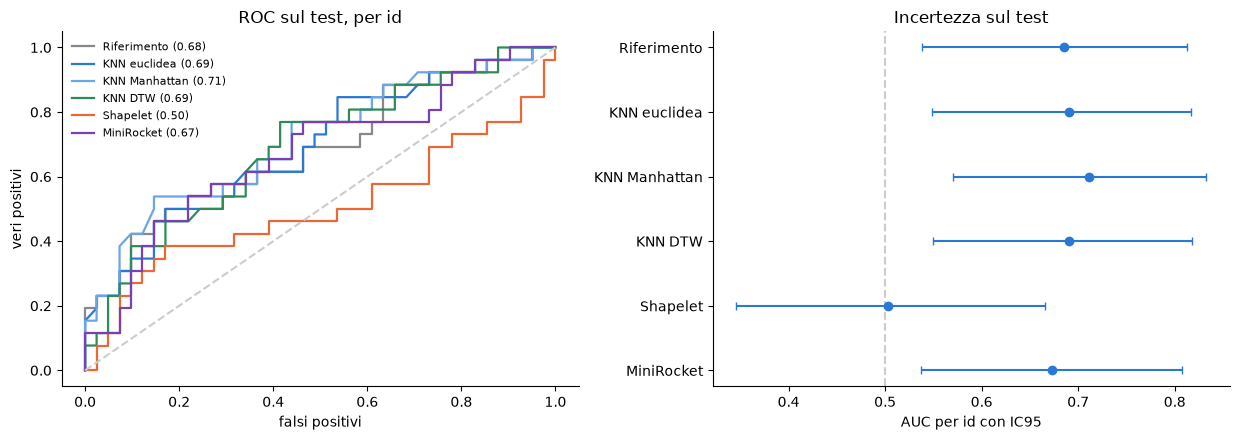

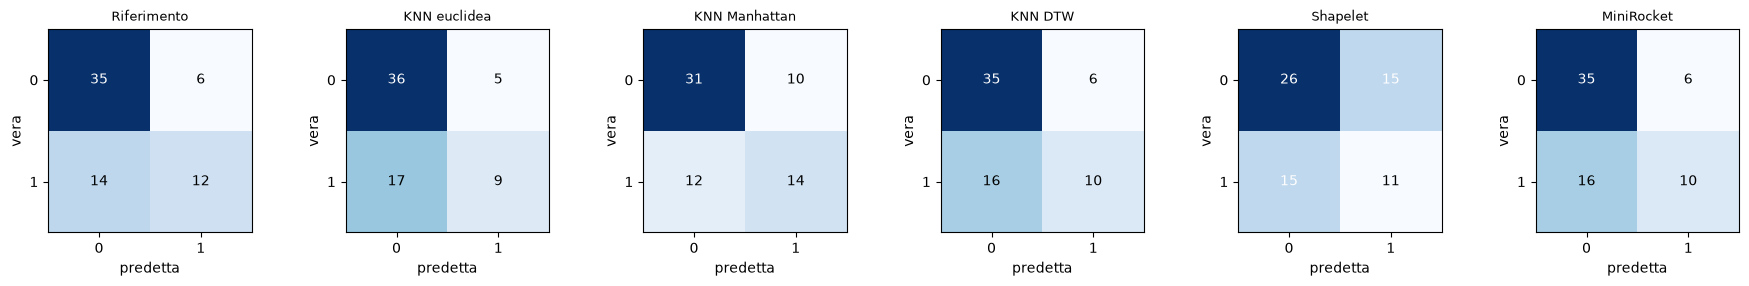

In [74]:
def best_row(tbl):
    return tbl.sort_values('AUC id', ascending=False).iloc[0]

best = {'KNN euclidea': best_row(knn_table[knn_table.metric == 'euclidean']),
        'KNN Manhattan': best_row(knn_table[knn_table.metric == 'manhattan']),
        'KNN DTW': best_row(dtw_table), 'MiniRocket': best_row(mr_table)}
cv_compare = pd.DataFrame(results + [{k_: r[k_] for k_ in ['famiglia', 'configurazione', 'AUC id', 'AUC finestra']} for r in best.values()])
print(cv_compare.sort_values('AUC id', ascending=False).round(3).to_string(index=False))

test_scores, oof_final = {}, {}
test_scores['Riferimento'] = fit_baseline(mean_enmo[tr], ytr).decision_function(mean_enmo[te]); oof_final['Riferimento'] = oof_store['baseline']
for fam, m_ in [('KNN euclidea', 'euclidean'), ('KNN Manhattan', 'manhattan')]:
    r = best[fam]
    Xr = reprs[r['rep']]
    test_scores[fam] = knn_test(pairwise_distances(Xr[te], Xr[tr], metric=m_, n_jobs=-1), int(r['k']))
    oof_final[fam] = oof_store[(fam, r['rep'], r['k'])]
r = best['KNN DTW']
rep_name, r_band = dtw_configs[r['cfg']]
D_te = dtw_matrix(reprs[rep_name][te], reprs[rep_name][tr], r_band).astype(np.float32)
test_scores['KNN DTW'] = knn_test(D_te, int(r['k'])); oof_final['KNN DTW'] = oof_store[('KNN DTW', r['cfg'], r['k'])]
test_scores['Shapelet'] = score_shp_te; oof_final['Shapelet'] = oof_store['shapelet']
r = best['MiniRocket']
Xm = mr_configs[r['configurazione']]
mr_f, clf_f = fit_minirocket(Xm[tr], ytr)
test_scores['MiniRocket'] = clf_f.decision_function(mr_f.transform(Xm[te])); oof_final['MiniRocket'] = oof_store[('MiniRocket', r['configurazione'])]

def bootstrap_auc(s_id, y_id, ref=None, n=2000, seed=SEED):
    rng = np.random.default_rng(seed); vals, diffs = [], []
    for _ in range(n):
        b = rng.integers(0, len(y_id), len(y_id))
        if len(np.unique(y_id[b])) < 2:
            continue
        vals.append(roc_auc_score(y_id[b], s_id[b]))
        if ref is not None:
            diffs.append(vals[-1] - roc_auc_score(y_id[b], ref[b]))
    return np.quantile(vals, [0.025, 0.975]), (np.quantile(diffs, [0.025, 0.975]) if ref is not None else None)

assert all(np.isfinite(v).all() for v in list(test_scores.values()) + list(oof_final.values()))
ref_id, _ = by_id(test_scores['Riferimento'], idte, yte)
rows_final, id_outputs = [], {}
for fam, s in test_scores.items():
    thr_w = best_threshold(oof_final[fam], ytr)
    oof_id, y_id_tr = by_id(oof_final[fam], idtr, ytr)
    thr_id = best_threshold(oof_id, y_id_tr)
    s_id, y_id = by_id(s, idte, yte)
    ci, dci = bootstrap_auc(s_id, y_id, None if fam == 'Riferimento' else ref_id)
    rows_final.append({'modello': fam,
                       'AUC CV (id)': roc_auc_score(y_id_tr, oof_id),
                       'AUC test (id)': roc_auc_score(y_id, s_id), 'IC95 inf': ci[0], 'IC95 sup': ci[1],
                       'diff. vs rif. IC95': '-' if dci is None else f'[{dci[0]:+.3f}, {dci[1]:+.3f}]',
                       'BA id': balanced_accuracy_score(y_id, s_id >= thr_id), 'F1 macro id': f1_score(y_id, s_id >= thr_id, average='macro'),
                       'AUC finestra': roc_auc_score(yte, s), 'BA finestra': balanced_accuracy_score(yte, s >= thr_w),
                       'F1 macro finestra': f1_score(yte, s >= thr_w, average='macro')})
    id_outputs[fam] = (s_id, y_id, thr_id)
final_table = pd.DataFrame(rows_final)
print(final_table.round(3).to_string(index=False))
print(f"test: {len(y_id)} id, di cui {int(y_id.sum())} in classe 1  |  {len(yte)} finestre")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
cols = ['#888888', C0, '#6aa5e8', '#2e8b57', C1, '#7a3fb0']
for (fam, (s_id, y_id, _)), col in zip(id_outputs.items(), cols):
    fpr, tpr, _ = roc_curve(y_id, s_id)
    axes[0].plot(fpr, tpr, color=col, linewidth=1.6, label=f'{fam} ({roc_auc_score(y_id, s_id):.2f})')
axes[0].plot([0, 1], [0, 1], color='#cccccc', linestyle='--')
axes[0].set_xlabel('falsi positivi'); axes[0].set_ylabel('veri positivi'); axes[0].set_title('ROC sul test, per id'); axes[0].legend(frameon=False, fontsize=8)
ft = final_table.iloc[::-1]
axes[1].errorbar(ft['AUC test (id)'], ft['modello'], xerr=[ft['AUC test (id)'] - ft['IC95 inf'], ft['IC95 sup'] - ft['AUC test (id)']], fmt='o', color=C0, capsize=3)
axes[1].axvline(0.5, color='#cccccc', linestyle='--')
axes[1].set_xlabel('AUC per id con IC95'); axes[1].set_title('Incertezza sul test')
for a_ in axes:
    a_.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(id_outputs), figsize=(3 * len(id_outputs), 2.8))
for ax, (fam, (s_id, y_id, thr)) in zip(axes, id_outputs.items()):
    cm = confusion_matrix(y_id, s_id >= thr)
    ax.imshow(cm, cmap='Blues')
    for (a_, b_), v in np.ndenumerate(cm):
        ax.text(b_, a_, v, ha='center', va='center', color='white' if v > cm.max() / 2 else 'black')
    ax.set_title(fam, fontsize=9); ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xlabel('predetta'); ax.set_ylabel('vera')
plt.tight_layout(); plt.show()

**Risultato:**

- **Nessun metodo batte in modo dimostrabile il riferimento.** Il riferimento ha AUC per id 0.685 sul test. KNN euclidea (0.691), Manhattan (0.711), DTW (0.690) e MiniRocket (0.673) sono tutti nello stesso intervallo, e l'IC95 della differenza rispetto al riferimento comprende sempre lo zero. Il primato di KNN Manhattan non è un risultato affidabile: gli intervalli sono ampi (circa ±0.13) perché il test ha solo 67 soggetti.
- **Conta il livello, non la forma.** In CV le configurazioni migliori di tutte le famiglie di KNN e di MiniRocket usano **enmo con il livello conservato**, con `k` alti (101-201). Un voto fra così tanti vicini equivale a stimare il livello di attività attorno alla finestra, quindi si avvicina al riferimento. Con la sola forma l'AUC in CV resta circa 0.58-0.61 per KNN. Va detto che per KNN euclidea il `k` migliore è al bordo della griglia.
- **Distanze.** La DTW non migliora la distanza euclidea, coerentemente con P4: le finestre sono già in fase, e la DTW libera sulla forma a 200 step è fra le peggiori (0.46-0.57 in CV). La banda di Sakoe-Chiba aiuta su questa rappresentazione, mentre la PAA non peggiora e spesso migliora i risultati, attenuando il rumore fra step vicini.
- **Più canali non aiutano.** Con MiniRocket i 5 canali (0.618 con il livello) vanno peggio del solo `enmo` (0.665).
- **Shapelet.** AUC 0.503 sul test contro 0.655 in CV, con IC95 da 0.35 a 0.67: su questo test non risultano migliori del caso. È il divario maggiore fra CV e test, coerente con il sovradattamento visto sopra, e non è stato corretto dopo aver visto il test.
- **Per finestra è più difficile.** L'AUC scende a 0.54-0.62: la singola giornata è rumorosa e la media fra giornate dello stesso soggetto aiuta.
- **Soglie.** BA e F1 macro per id arrivano a circa 0.61-0.66 con la soglia scelta in CV, esclusi gli shapelet (0.53): migliori del caso ma lontane da un uso pratico.

## CONCLUSIONI

1. **Struttura dei dati.** 4437 finestre ma solo 494 soggetti (335 dopo la pulizia): split e test statistici vanno fatti per id. Una finestra si comporta come **un ciclo giorno-notte**, non come 100 ore contigue. Questo punto contrasta in parte con le istruzioni e va confermato con il docente.
2. **Il segnale è il livello di attività diurna.** La classe problematica si muove meno di giorno, non di notte. Tutte le analisi portano qui: il test per id di P9, il K-means euclideo (38% contro 21% di classe 1) e i KNN che conservano il livello.
3. **La forma aggiunge poco.** Motif, contrasto, clustering di forma e shapelet non trovano un pattern tipico di una classe.
4. **Classificazione.** Il migliore arriva ad AUC per id attorno a 0.7, ma una regressione logistica sul solo `enmo` medio (0.685) non è distinguibile dai metodi più complessi. Il segnale esiste, ma è debole e non basta per una classificazione individuale.

**Limiti:**

- il test ha 67 soggetti, quindi gli intervalli di confidenza sono ampi;
- lo scarto delle finestre con non-wear lascia soprattutto soggetti con registrazioni lunghe e complete;
- l'associazione è correlazionale e non dice nulla sulla causa;
- `enmo` è sensibile al polso e al modo in cui il dispositivo viene indossato;
- ore, notte e giorno dipendono dall'interpretazione di P4.